# CC1 – Réseaux de neurones sur le dataset **Iris**
**Partie 1 : `sklearn` – `MLPClassifier`**  |  **Partie 2 : `TensorFlow` – `GradientTape`**  |  **Partie 3 : `Keras` – `Sequential`**  |  **Partie 4 : Comparaison des accuracy**

Plan :
1. Import et chargement des données
2. Exploration et nettoyage
3. Visualisation
4. Prétraitement
5. MLPClassifier (sklearn) + optimisation
6. TensorFlow avec `tf.GradientTape` (boucle d'entraînement manuelle)
7. Keras `Sequential` (`compile` / `fit`)
8. Comparaison des accuracy

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", palette="Set2")
print("TensorFlow :", tf.__version__)x²

TensorFlow : 2.18.0


## 1. Chargement des données

In [4]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Exploration et nettoyage

In [6]:
print("Dimensions :", df.shape)
df.info()
display(df.describe().T)

Dimensions : (150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
 5   species            150 non-null    object 
dtypes: float64(4), int32(1), object(1)
memory usage: 6.6+ KB


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


In [7]:
# Valeurs manquantes, doublons, équilibre des classes
print("Valeurs manquantes :\n", df.isna().sum(), "\n")
print("Doublons :", df.duplicated().sum())
print("\nRépartition des classes :\n", df["species"].value_counts())

Valeurs manquantes :
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64 

Doublons : 1

Répartition des classes :
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [8]:
# Nettoyage : suppression des doublons
avant = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"{avant - len(df)} ligne(s) dupliquée(s) supprimée(s) -> {len(df)} lignes restantes")

# Détection des outliers (méthode IQR)
features = iris.feature_names
Q1, Q3 = df[features].quantile(0.25), df[features].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[features] < Q1 - 1.5*IQR) | (df[features] > Q3 + 1.5*IQR)).sum()
print("\nOutliers par variable :\n", outliers)
# Peu d'outliers et valeurs réalistes (mesures botaniques) -> on les conserve

1 ligne(s) dupliquée(s) supprimée(s) -> 149 lignes restantes

Outliers par variable :
 sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


## 3. Visualisation

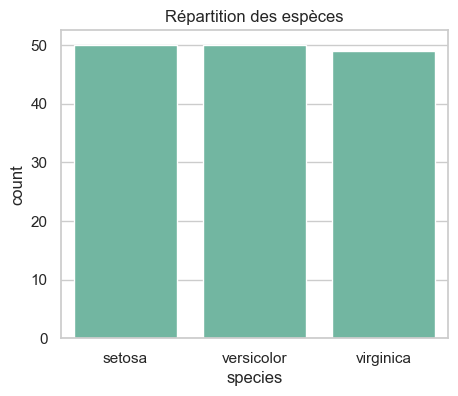

In [10]:
# Distribution des classes
plt.figure(figsize=(5,4))
sns.countplot(data=df, x="species")
plt.title("Répartition des espèces"); plt.show()

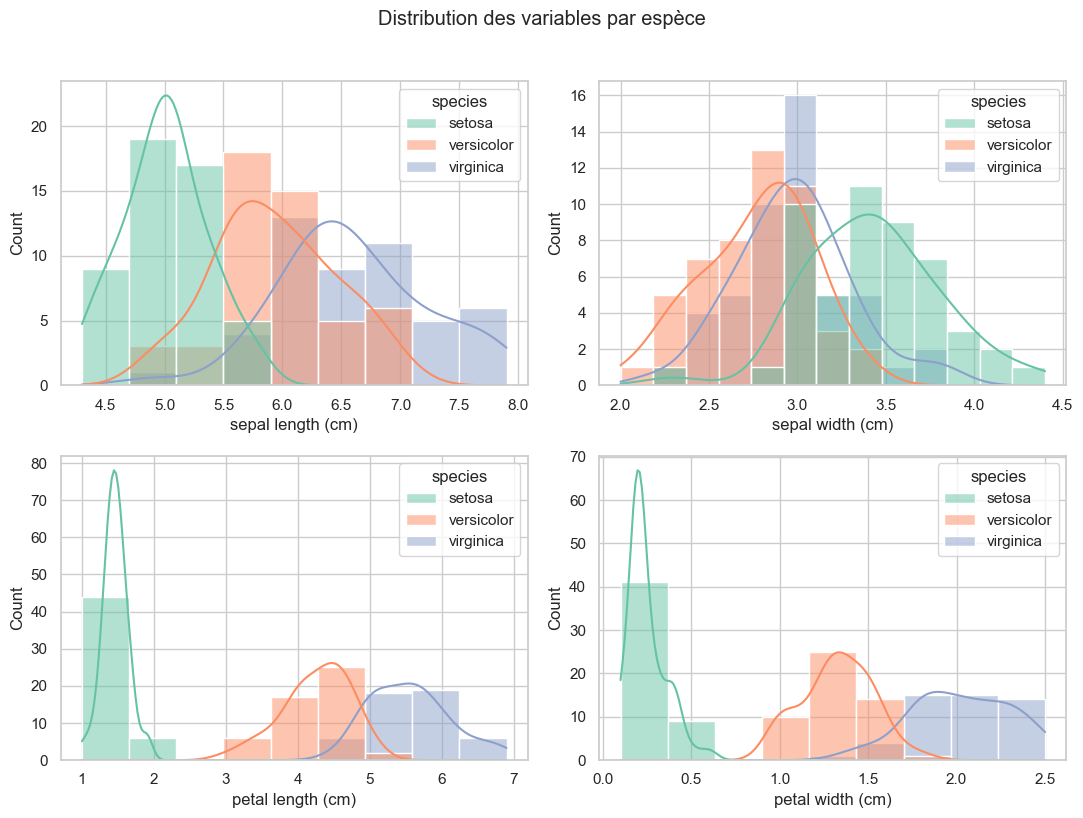

In [11]:
# Histogrammes par variable et par espèce
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.ravel(), features):
    sns.histplot(data=df, x=f, hue="species", kde=True, ax=ax)
plt.suptitle("Distribution des variables par espèce", y=1.02); plt.tight_layout(); plt.show()

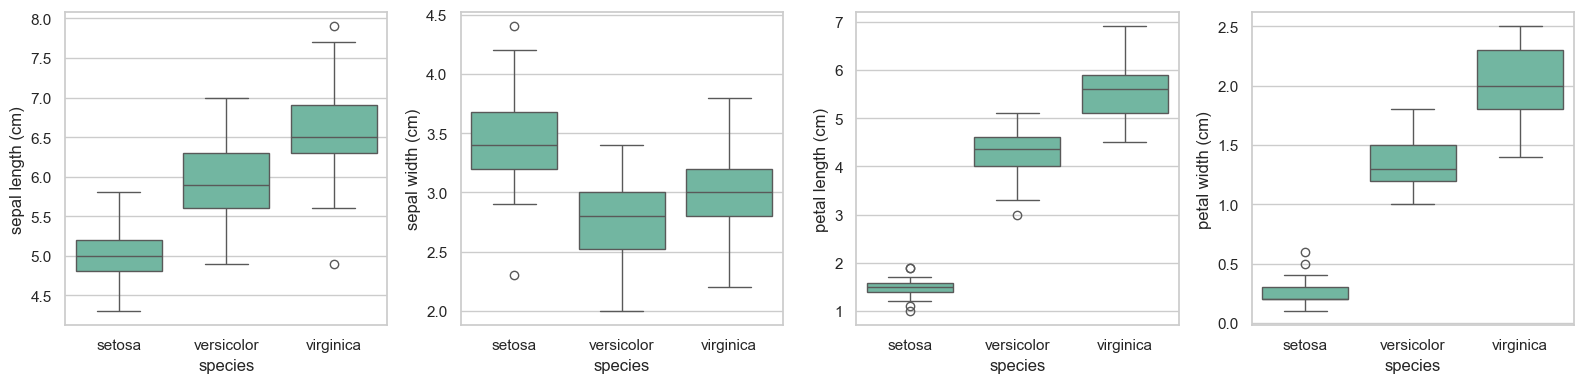

In [12]:
# Boxplots
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, features):
    sns.boxplot(data=df, x="species", y=f, ax=ax)
plt.tight_layout(); plt.show()

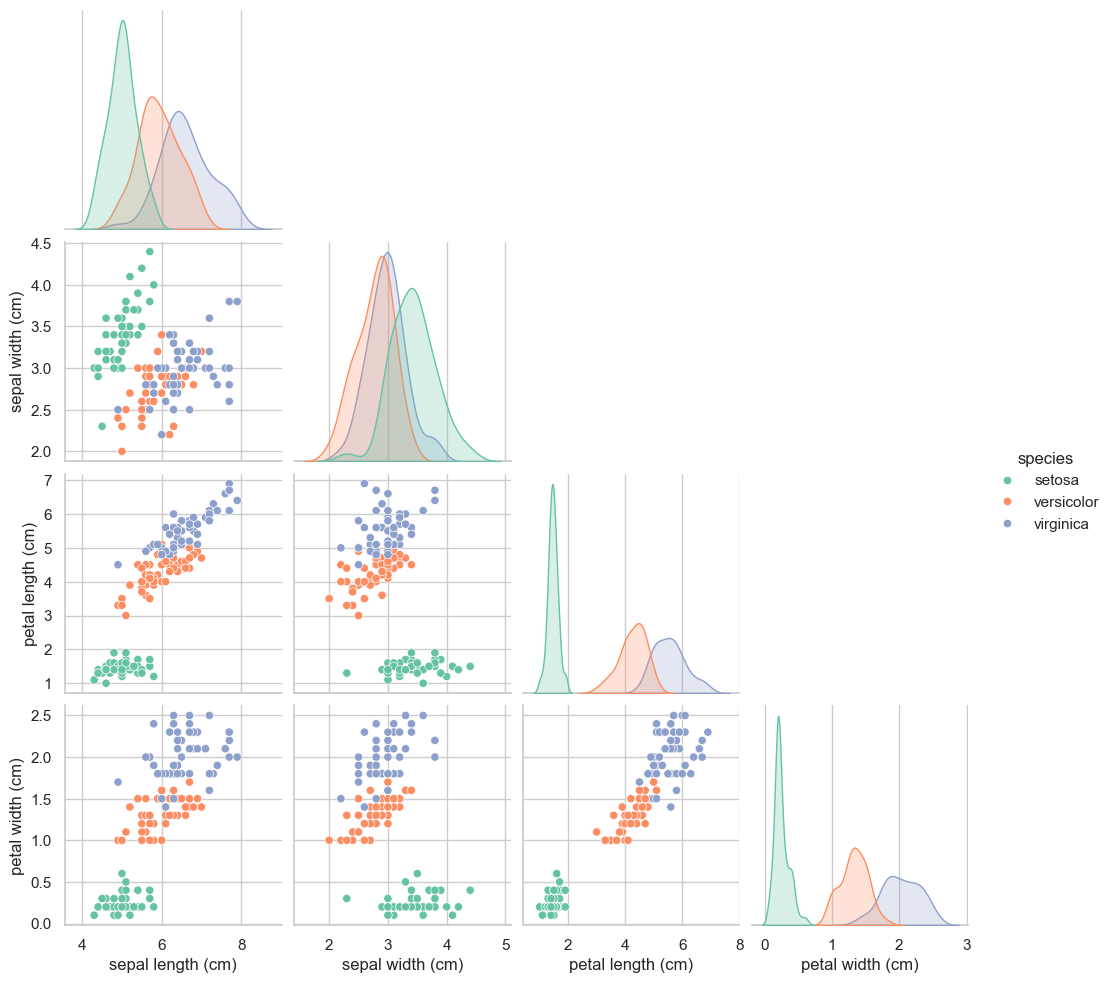

In [13]:
# Pairplot
sns.pairplot(df.drop(columns="target"), hue="species", corner=True)
plt.show()

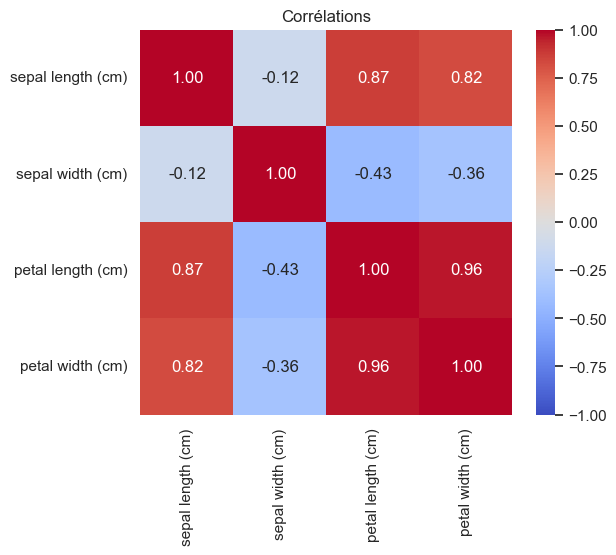

In [14]:
# Matrice de corrélation
plt.figure(figsize=(6,5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Corrélations"); plt.show()

## 4. Prétraitement
- Séparation features / cible
- Découpage **train / test stratifié** (80 / 20)
- **Standardisation** (indispensable pour les réseaux de neurones) : le scaler est ajusté uniquement sur le train pour éviter la fuite de données
- Encodage *one-hot* de la cible pour Keras

In [16]:
X = df[features].values
y = df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

y_train_oh = keras.utils.to_categorical(y_train, 3)
y_test_oh  = keras.utils.to_categorical(y_test, 3)

print("Train :", X_train_s.shape, "| Test :", X_test_s.shape)

Train : (119, 4) | Test : (30, 4)


## 5. sklearn – `MLPClassifier`

In [18]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                    max_iter=1000, random_state=SEED)
mlp.fit(X_train_s, y_train)

y_pred_mlp = mlp.predict(X_test_s)
acc_mlp = accuracy_score(y_test, y_pred_mlp)
print(f"Accuracy MLPClassifier (base) : {acc_mlp:.4f}")
print(classification_report(y_test, y_pred_mlp, target_names=iris.target_names))

Accuracy MLPClassifier (base) : 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



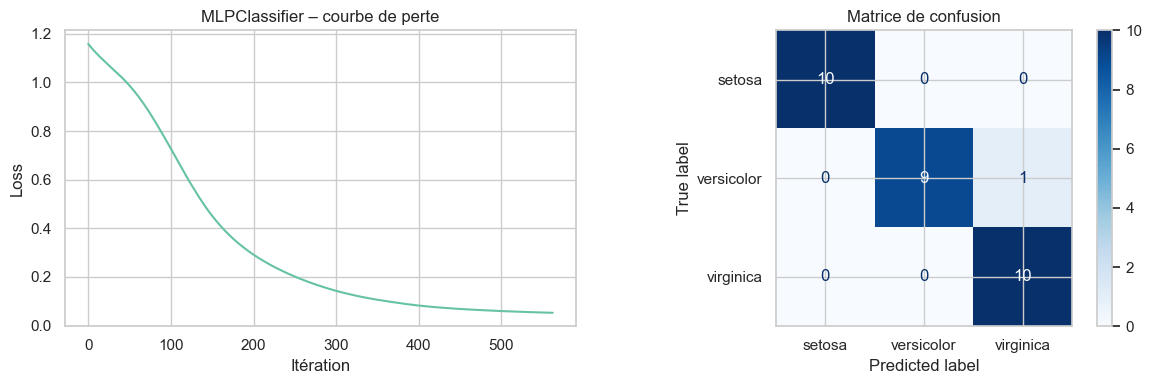

In [19]:
# Courbe de perte + matrice de confusion
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(mlp.loss_curve_); ax[0].set_title("MLPClassifier – courbe de perte")
ax[0].set_xlabel("Itération"); ax[0].set_ylabel("Loss")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_mlp), display_labels=iris.target_names).plot(ax=ax[1], cmap="Blues")
ax[1].set_title("Matrice de confusion"); plt.tight_layout(); plt.show()

In [20]:
# Optimisation des hyperparamètres (GridSearchCV, validation croisée 5 plis)
param_grid = {
    "hidden_layer_sizes": [(8,), (16,), (16, 8), (32, 16)],
    "activation": ["relu", "tanh"],
    "alpha": [1e-4, 1e-2],
    "learning_rate_init": [1e-3, 1e-2],
}
grid = GridSearchCV(MLPClassifier(max_iter=1000, random_state=SEED),
                    param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print(f"Accuracy CV : {grid.best_score_:.4f}")
best_mlp = grid.best_estimator_
acc_mlp_best = accuracy_score(y_test, best_mlp.predict(X_test_s))
print(f"Accuracy test (MLP optimisé) : {acc_mlp_best:.4f}")

Meilleurs paramètres : {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.01}
Accuracy CV : 0.9667
Accuracy test (MLP optimisé) : 0.9333


## 6. TensorFlow – `tf.GradientTape`
Ici on n'utilise **pas** `Sequential` ni `fit` : on écrit nous-mêmes
1. les **poids** (`tf.Variable`) et la **propagation avant** (forward),
2. la **fonction de perte** (cross-entropy),
3. la **rétropropagation** avec `tf.GradientTape` (calcul automatique des gradients),
4. la **mise à jour des poids** avec un optimiseur Adam,
5. un **early stopping** manuel sur un jeu de validation.

In [22]:
# Jeu de validation (20 % du train) pour l'early stopping
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train, test_size=0.2,
                                            random_state=SEED, stratify=y_train)
X_tr, X_val = tf.constant(X_tr, tf.float32), tf.constant(X_val, tf.float32)
y_tr_oh  = tf.one_hot(y_tr, 3);  y_val_oh = tf.one_hot(y_val, 3)

# Paramètres du réseau 4 -> 16 -> 8 -> 3 (initialisation de Glorot)
def init_params(sizes):
    init = tf.keras.initializers.GlorotUniform(seed=SEED)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        params += [tf.Variable(init((n_in, n_out)), name="W"),
                   tf.Variable(tf.zeros((n_out,)),  name="b")]
    return params

def forward(x, params):
    W1, b1, W2, b2, W3, b3 = params
    h1 = tf.nn.relu(x @ W1 + b1)
    h2 = tf.nn.relu(h1 @ W2 + b2)
    return h2 @ W3 + b3            # logits (le softmax est dans la loss)

def loss_fn(y_true_oh, logits):
    return tf.reduce_mean(tf.nn.softmax_cross_entropy_with_logits(labels=y_true_oh, logits=logits))

def accuracy_fn(y_true_oh, logits):
    return tf.reduce_mean(tf.cast(tf.equal(tf.argmax(logits, 1), tf.argmax(y_true_oh, 1)), tf.float32))

params_gt = init_params([4, 16, 8, 3])
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-2)

@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:                 # enregistre les opérations
        logits = forward(xb, params_gt)
        loss = loss_fn(yb, logits)
    grads = tape.gradient(loss, params_gt)          # rétropropagation
    optimizer.apply_gradients(zip(grads, params_gt))  # mise à jour des poids
    return loss

In [23]:
EPOCHS, BATCH, PATIENCE = 300, 16, 20
train_ds = tf.data.Dataset.from_tensor_slices((X_tr, y_tr_oh)).shuffle(len(X_tr), seed=SEED).batch(BATCH)

hist_gt = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
best_val, wait, best_weights = np.inf, 0, None

for epoch in range(EPOCHS):
    for xb, yb in train_ds:
        train_step(xb, yb)

    tr_logits, val_logits = forward(X_tr, params_gt), forward(X_val, params_gt)
    hist_gt["loss"].append(float(loss_fn(y_tr_oh, tr_logits)))
    hist_gt["val_loss"].append(float(loss_fn(y_val_oh, val_logits)))
    hist_gt["acc"].append(float(accuracy_fn(y_tr_oh, tr_logits)))
    hist_gt["val_acc"].append(float(accuracy_fn(y_val_oh, val_logits)))

    # Early stopping manuel
    if hist_gt["val_loss"][-1] < best_val - 1e-4:
        best_val, wait = hist_gt["val_loss"][-1], 0
        best_weights = [p.numpy() for p in params_gt]
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping à l'epoch {epoch+1}"); break

for p, w in zip(params_gt, best_weights):   # restauration des meilleurs poids
    p.assign(w)
print("Epochs effectuées :", len(hist_gt["loss"]))

Early stopping à l'epoch 41
Epochs effectuées : 41


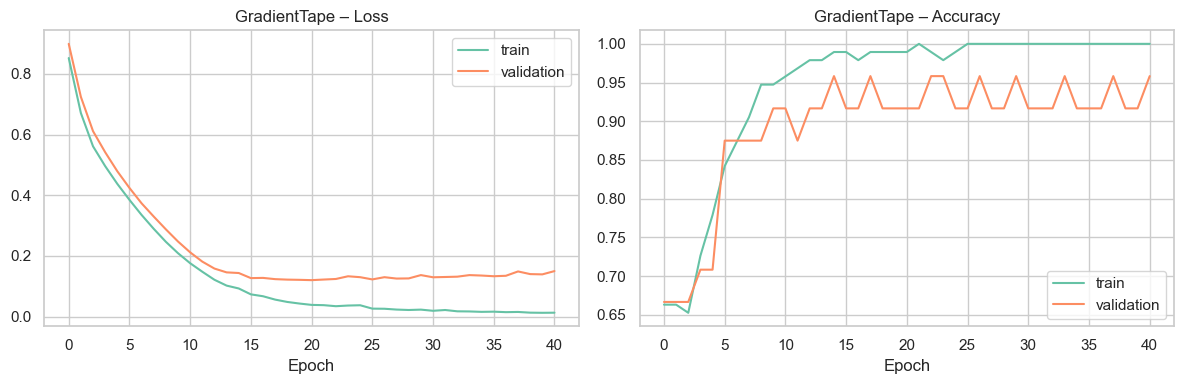

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_gt["loss"], label="train"); ax[0].plot(hist_gt["val_loss"], label="validation")
ax[0].set_title("GradientTape – Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist_gt["acc"], label="train"); ax[1].plot(hist_gt["val_acc"], label="validation")
ax[1].set_title("GradientTape – Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Accuracy TensorFlow GradientTape (test) : 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



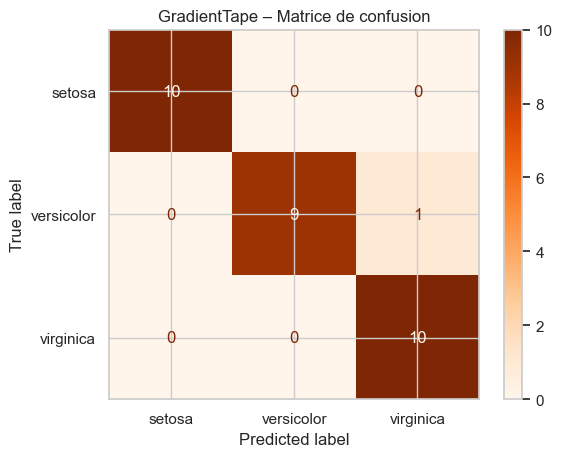

In [25]:
logits_test = forward(tf.constant(X_test_s, tf.float32), params_gt)
y_pred_gt = np.argmax(logits_test.numpy(), axis=1)
acc_gt = accuracy_score(y_test, y_pred_gt)
print(f"Accuracy TensorFlow GradientTape (test) : {acc_gt:.4f}")
print(classification_report(y_test, y_pred_gt, target_names=iris.target_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_gt), display_labels=iris.target_names).plot(cmap="Oranges")
plt.title("GradientTape – Matrice de confusion"); plt.show()

## 7. Keras – `Sequential`

In [27]:
model = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="softmax"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-2),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [28]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
history = model.fit(X_train_s, y_train_oh, validation_split=0.2,
                    epochs=300, batch_size=16, callbacks=[early], verbose=0)
print("Epochs effectuées :", len(history.history["loss"]))

Epochs effectuées : 91


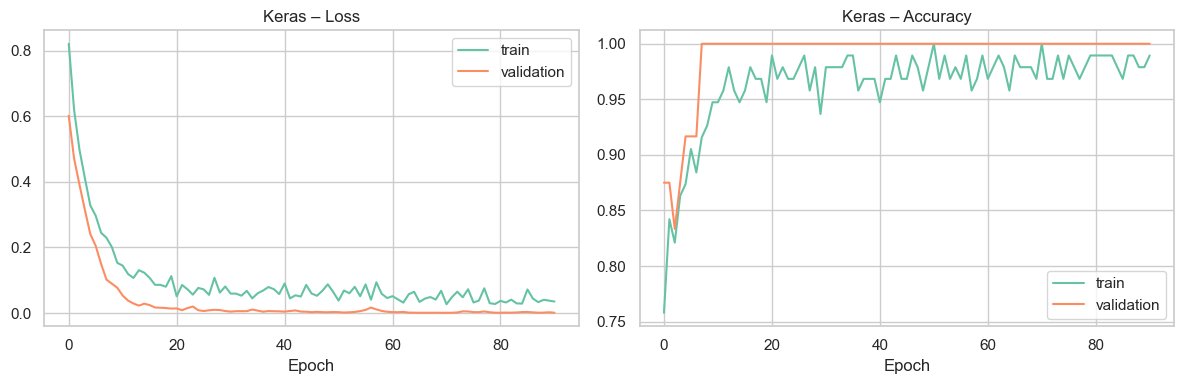

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Keras – Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Keras – Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Accuracy Keras (test) : 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



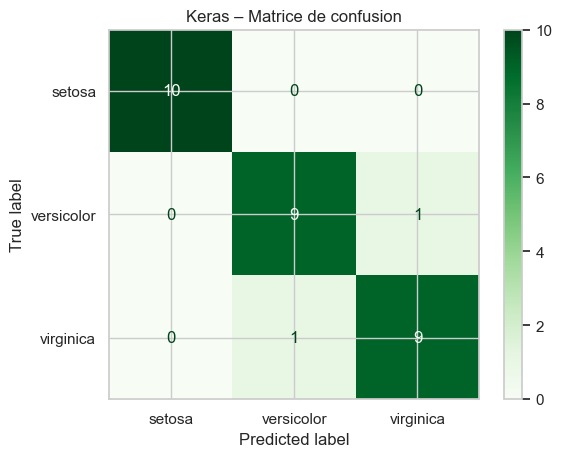

In [30]:
loss, acc_keras = model.evaluate(X_test_s, y_test_oh, verbose=0)
y_pred_keras = np.argmax(model.predict(X_test_s, verbose=0), axis=1)
print(f"Accuracy Keras (test) : {acc_keras:.4f}")
print(classification_report(y_test, y_pred_keras, target_names=iris.target_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_keras), display_labels=iris.target_names).plot(cmap="Greens")
plt.title("Keras – Matrice de confusion"); plt.show()

## 8. Comparaison des accuracy

,Modèle,Accuracy test
0,sklearn MLPClassifier (base),0.966667
2,TensorFlow GradientTape,0.966667
3,Keras Sequential,0.933333
1,sklearn MLPClassifier (GridSearch),0.933333


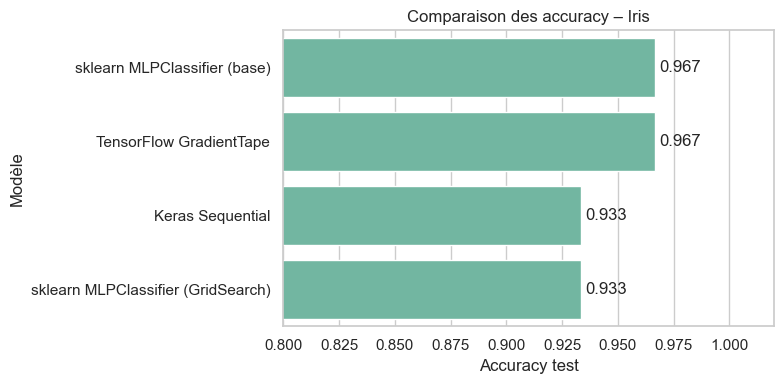

In [32]:
results = pd.DataFrame({
    "Modèle": ["sklearn MLPClassifier (base)", "sklearn MLPClassifier (GridSearch)",
               "TensorFlow GradientTape", "Keras Sequential"],
    "Accuracy test": [acc_mlp, acc_mlp_best, acc_gt, acc_keras],
}).sort_values("Accuracy test", ascending=False)
display(results)

plt.figure(figsize=(8,4))
ax = sns.barplot(data=results, x="Accuracy test", y="Modèle")
ax.set_xlim(0.8, 1.02)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", padding=3)
plt.title("Comparaison des accuracy – Iris"); plt.tight_layout(); plt.show()

In [33]:
# Robustesse : le jeu de test est petit (≈30 échantillons) -> validation croisée sklearn
from sklearn.pipeline import make_pipeline
cv_scores = cross_val_score(make_pipeline(StandardScaler(),
                            MLPClassifier(**grid.best_params_, max_iter=1000, random_state=SEED)),
                            X, y, cv=10)   # pipeline : le scaler est ajusté à chaque pli (pas de fuite)
print(f"Accuracy CV 10 plis (sklearn) : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Accuracy CV 10 plis (sklearn) : 0.9533 ± 0.0427


## Conclusion
- Iris est un dataset simple et presque linéairement séparable : les trois approches atteignent des accuracy très proches (≈ 93 – 100 %).
- Les erreurs éventuelles concernent *versicolor* / *virginica*, les deux classes qui se chevauchent (visible sur le pairplot).
- `sklearn` est le plus rapide à mettre en œuvre ; `Keras Sequential` est concis (`compile`/`fit`) ; `GradientTape` demande plus de code mais donne un **contrôle total** sur la boucle d'entraînement (utile pour la recherche, les pertes personnalisées, etc.).
- Avec un jeu de test aussi petit, l'écart entre modèles n'est pas statistiquement significatif.